# Sistema experto difuso para la identificación de minerales
**María Luisa Costas** · Lic. en Ciencias Biológicas (FaCENA-UNNE) · Tec. en Ciencia de Datos (UNDEC)

Un **sistema experto** guarda el conocimiento de un especialista en forma de reglas *si… entonces…*. Un sistema **difuso** permite que las propiedades no sean "sí o no" sino de grado: un mineral puede ser *bastante claro* o *algo oscuro*.

Este sistema recibe tres propiedades observables (color, brillo y dureza) y devuelve qué minerales son compatibles y con qué grado.

> Versión mejorada del trabajo práctico original, revisada con asistencia de IA. Los cambios y el motivo de cada uno están al final.

In [1]:
!pip install -q scikit-fuzzy

## 1. Variables de entrada

| Variable | Escala | Cómo se mide |
|---|---|---|
| Color | 0 (muy claro) a 10 (muy oscuro) | Apreciación visual de la muestra |
| Brillo | 0 (no metálico) a 10 (metálico) | Aspecto de la superficie fresca |
| Dureza | 1 a 10 | **Escala de Mohs** (talco = 1, cuarzo = 7) |

In [2]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt
import pandas as pd

# Universos de las variables
color_u  = np.arange(0, 10.01, 0.1)
brillo_u = np.arange(0, 10.01, 0.1)
dureza_u = np.arange(1, 10.01, 0.1)   # escala de Mohs

# Funciones de pertenencia (cada conjunto dice "cuánto" pertenece un valor a una categoría)
color = {
    'claro':  fuzz.trapmf(color_u, [0, 0, 2, 5]),
    'medio':  fuzz.trimf(color_u,  [2, 5, 8]),
    'oscuro': fuzz.trapmf(color_u, [5, 8, 10, 10]),
}
brillo = {
    'no_metalico': fuzz.trapmf(brillo_u, [0, 0, 2, 5]),
    'metalico':    fuzz.trapmf(brillo_u, [5, 8, 10, 10]),
}
dureza = {
    'muy_blando':   fuzz.trimf(dureza_u,  [1, 1, 2]),
    'blando':       fuzz.trapmf(dureza_u, [1.5, 2, 2.7, 3.5]),
    'medio_blando': fuzz.trapmf(dureza_u, [2.7, 3, 3.5, 4.5]),
    'medio_duro':   fuzz.trapmf(dureza_u, [5, 6, 6.5, 7]),
    'duro':         fuzz.trapmf(dureza_u, [6.5, 7, 10, 10]),
}

### Cómo se ven las funciones de pertenencia

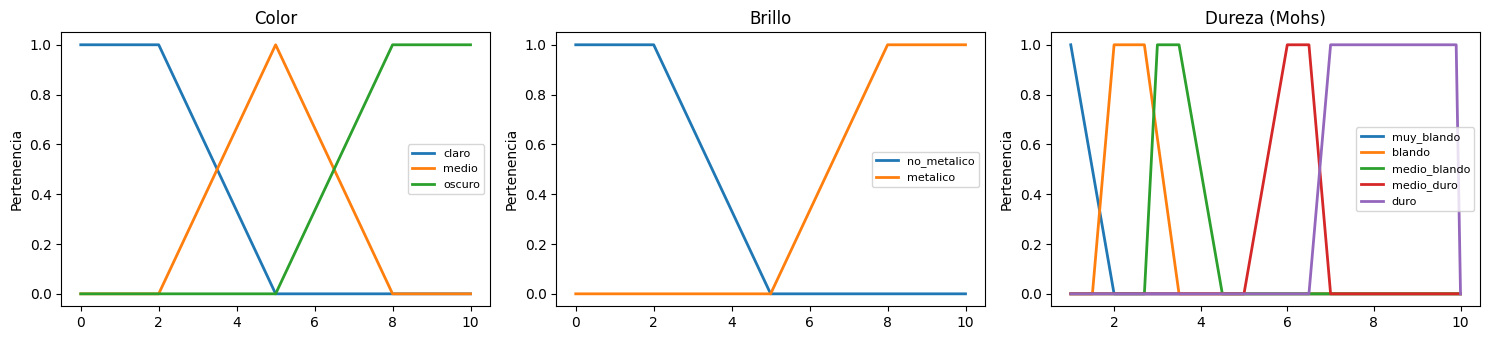

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (titulo, universo, conjuntos) in zip(
        axes, [('Color', color_u, color), ('Brillo', brillo_u, brillo), ('Dureza (Mohs)', dureza_u, dureza)]):
    for nombre, valores in conjuntos.items():
        ax.plot(universo, valores, label=nombre, linewidth=2)
    ax.set_title(titulo); ax.set_ylabel('Pertenencia'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2. Base de reglas

Cada regla dice: *SI* color es X *Y* brillo es Y *Y* dureza es Z, *ENTONCES* el mineral es M.

Las propiedades de referencia (dureza de Mohs y brillo) son valores estándar de mineralogía. **Conviene verificarlas contra tu bibliografía de cátedra.**

| Mineral | Color | Brillo | Dureza (Mohs) |
|---|---|---|---|
| Talco | claro | no metálico | 1 |
| Yeso | claro | no metálico | 2 |
| Baritina | claro | no metálico | 3 – 3,5 |
| Cuarzo | claro | no metálico | 7 |
| Galena | oscuro | metálico | 2,5 |
| Pirita | medio | metálico | 6 – 6,5 |

In [4]:
REGLAS = {
    'Talco':    ('claro',  'no_metalico', 'muy_blando'),
    'Yeso':     ('claro',  'no_metalico', 'blando'),
    'Baritina': ('claro',  'no_metalico', 'medio_blando'),
    'Cuarzo':   ('claro',  'no_metalico', 'duro'),
    'Galena':   ('oscuro', 'metalico',    'blando'),
    'Pirita':   ('medio',  'metalico',    'medio_duro'),
}

def identificar(c, b, d, umbral=0.05):
    """Devuelve los minerales compatibles ordenados por grado de compatibilidad (0 a 1)."""
    mc = {k: fuzz.interp_membership(color_u,  v, c) for k, v in color.items()}
    mb = {k: fuzz.interp_membership(brillo_u, v, b) for k, v in brillo.items()}
    md_ = {k: fuzz.interp_membership(dureza_u, v, d) for k, v in dureza.items()}

    resultados = []
    for mineral, (rc, rb, rd) in REGLAS.items():
        grado = min(mc[rc], mb[rb], md_[rd])      # el "Y" difuso es el mínimo
        if grado >= umbral:
            resultados.append((mineral, round(float(grado), 2)))
    return sorted(resultados, key=lambda x: x[1], reverse=True)

def mostrar(c, b, d):
    res = identificar(c, b, d)
    print(f"Color={c}  Brillo={b}  Dureza={d}")
    if not res:
        print("  → Sin coincidencia clara: ninguna regla se activa. Revisar las propiedades o ampliar la base de reglas.\n")
        return
    for mineral, grado in res:
        print(f"  → {mineral}: compatibilidad {grado:.0%}")
    print()

## 3. Casos de prueba

In [5]:
casos = [
    ('Talco típico',      1, 1, 1),
    ('Yeso típico',       0.5, 1, 2),
    ('Baritina típica',   1.5, 1, 3.25),
    ('Cuarzo típico',     1, 1, 7),
    ('Galena típica',     8, 9, 2.5),
    ('Pirita típica',     5, 9, 6.25),
    ('Caso intermedio',   3, 3, 2.5),
    ('Caso 5-5-5 (el que fallaba antes)', 5, 5, 5),
]
for nombre, c, b, d in casos:
    print(f"## {nombre}")
    mostrar(c, b, d)

## Talco típico
Color=1  Brillo=1  Dureza=1
  → Talco: compatibilidad 100%

## Yeso típico
Color=0.5  Brillo=1  Dureza=2
  → Yeso: compatibilidad 100%

## Baritina típica
Color=1.5  Brillo=1  Dureza=3.25
  → Baritina: compatibilidad 100%
  → Yeso: compatibilidad 31%

## Cuarzo típico
Color=1  Brillo=1  Dureza=7
  → Cuarzo: compatibilidad 100%

## Galena típica
Color=8  Brillo=9  Dureza=2.5
  → Galena: compatibilidad 100%

## Pirita típica
Color=5  Brillo=9  Dureza=6.25
  → Pirita: compatibilidad 100%

## Caso intermedio
Color=3  Brillo=3  Dureza=2.5
  → Yeso: compatibilidad 67%

## Caso 5-5-5 (el que fallaba antes)
Color=5  Brillo=5  Dureza=5
  → Sin coincidencia clara: ninguna regla se activa. Revisar las propiedades o ampliar la base de reglas.



## 4. Uso interactivo

Ejecutá esta celda para ingresar tus propias mediciones.

In [6]:
def iniciar_identificacion():
    print("== Sistema experto difuso para reconocimiento de minerales ==")
    try:
        c = float(input("Color (0=claro, 10=oscuro): "))
        b = float(input("Brillo (0=no metálico, 10=metálico): "))
        d = float(input("Dureza de Mohs (1 a 10): "))
        if not (0 <= c <= 10 and 0 <= b <= 10 and 1 <= d <= 10):
            print("Valores fuera de rango."); return
        mostrar(c, b, d)
    except ValueError:
        print("Entrada inválida: ingresá números.")

# iniciar_identificacion()   # descomentá esta línea para usarlo

## 5. Qué se cambió respecto de la versión original

1. **El caso 5-5-5 fallaba** porque ninguna regla cubría esos valores y el motor devolvía un error genérico. Ahora el sistema responde explícitamente "sin coincidencia clara".
2. **El cuarzo estaba definido como oscuro y metálico**, pero es incoloro a claro y de brillo vítreo (no metálico). Se corrigió la regla.
3. **La dureza usaba una escala 0–10 inventada.** Se reemplazó por la escala de Mohs, de modo que cada mineral tenga su valor real (por ejemplo, la baritina tiene 3–3,5 y no 6).
4. **Los umbrales de decisión no coincidían con los conjuntos de salida.** En lugar de promediar y cortar en 2, 4 y 6, ahora se calcula el grado de compatibilidad de cada regla y se ordenan los resultados, lo que permite ver alternativas cercanas.
5. Se agregaron **galena y pirita**, que son metálicas, para que la variable brillo realmente discrimine.
6. Se agregaron gráficos de las funciones de pertenencia y casos de prueba.

## 6. Limitaciones y próximos pasos

- Solo hay 6 minerales y 3 propiedades; en la práctica se usan además la raya, la densidad y el clivaje.
- El color es una escala subjetiva; se podría reemplazar por la raya o por valores medidos con la cámara.
- Próximo paso posible: agregar más minerales y evaluar el sistema con muestras reales de la colección de la cátedra.